# Experiment 21: Factor Analysis and Latent Factor Interpretation

An HR team surveys 300 employees on ten satisfaction questions. We simulate answers from three hidden themes—compensation, work culture and growth—then compare factor analysis with PCA and rotate the factor loadings for easier interpretation.

**Tools:** Scikit-learn, NumPy, Pandas, Matplotlib, SciPy.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Explore survey responses and correlations.  2. Fit FactorAnalysis with 2, 3 and 4 factors.  3. Apply varimax rotation and plot loadings.  4. Name factors from their strongest questions.  5. Compare factor analysis with PCA.

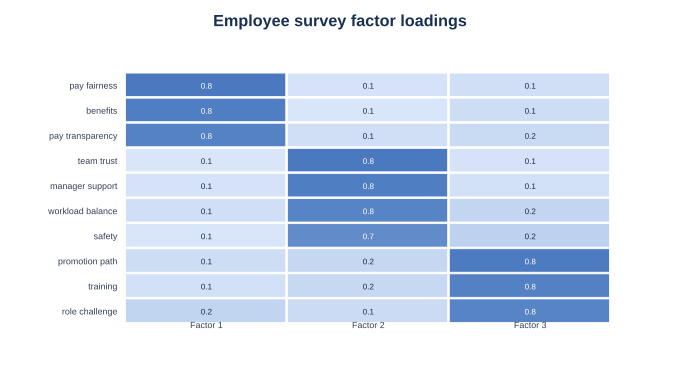

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import FactorAnalysis, PCA
from scipy.stats import zscore

rng=np.random.default_rng(21)
n=300
latent=rng.normal(size=(n,3))
loadings=np.array([
 [ .85,.05,.10],[.80,.10,.05],[.75,.10,.15],  # pay
 [ .05,.85,.10],[.10,.80,.10],[.10,.75,.15],[.05,.70,.20], # culture
 [ .05,.10,.85],[.10,.10,.80],[.15,.15,.75]  # growth
])
responses=latent@loadings.T+rng.normal(0,.45,(n,10))
responses=np.clip(np.rint(3+responses),1,5)
questions=["salary fairness","benefits","pay transparency","team trust","manager support",
 "workload balance","psychological safety","promotion path","training access","role challenge"]
df=pd.DataFrame(responses,columns=questions)
print(df.describe().round(2).loc[["mean","std","min","max"]])
corr=df.corr()
plt.figure(figsize=(9,7));plt.imshow(corr,cmap="coolwarm",vmin=-1,vmax=1)
plt.xticks(range(10),questions,rotation=70,ha="right");plt.yticks(range(10),questions)
plt.colorbar(label="Correlation");plt.title("Employee-question correlation matrix")
plt.tight_layout();plt.show()

def varimax(Phi,gamma=1.0,q=30,tol=1e-6):
    p,k=Phi.shape;R=np.eye(k);old=0
    for _ in range(q):
        lam=Phi@R
        u,s,vh=np.linalg.svd(Phi.T@(lam**3-(gamma/p)*lam@np.diag(np.diag(lam.T@lam))))
        R=u@vh
        value=s.sum()
        if old and value-old<tol:break
        old=value
    return Phi@R
Z=zscore(df,axis=0)
for k in [2,3,4]:
    fa=FactorAnalysis(n_components=k,random_state=21).fit(Z)
    rotated=varimax(fa.components_.T)
    print(f"\n{k} factors: mean log-likelihood={fa.score(Z):.3f}")
    for j in range(k):
        top=np.argsort(np.abs(rotated[:,j]))[-3:][::-1]
        groups=[("Compensation",set(range(0,3))),("Work Culture",set(range(3,7))),("Growth and Development",set(range(7,10)))]
        theme=max(groups,key=lambda g:sum(i in g[1] for i in top))[0]
        print(f"Factor {j+1} ({theme}) strongest items:",[questions[i] for i in top])
    if k==3: best_loadings=rotated
fig,axes=plt.subplots(1,2,figsize=(13,5))
im=axes[0].imshow(best_loadings,cmap="coolwarm",vmin=-1,vmax=1,aspect="auto")
axes[0].set_xticks(range(3),["Factor 1","Factor 2","Factor 3"])
axes[0].set_yticks(range(10),questions);axes[0].set_title("Varimax-rotated loadings")
fig.colorbar(im,ax=axes[0])
pca=PCA(n_components=3).fit(Z)
axes[1].bar(range(1,4),pca.explained_variance_ratio_*100)
axes[1].set(xticks=[1,2,3],xlabel="Principal component",ylabel="Variance explained (%)",
            title="PCA variance (same survey)")
plt.tight_layout();plt.show()